In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/features.csv")
X = df.drop(columns=["CONS_NO", "FLAG"])
y = df["FLAG"]

X_log = np.log1p(X)                       # shrink very large values
X_scaled = StandardScaler().fit_transform(X_log)
print(X_scaled.shape)

(42289, 19)


k=2  silhouette=0.280
k=3  silhouette=0.257
k=4  silhouette=0.262
k=5  silhouette=0.266
k=6  silhouette=0.231
k=7  silhouette=0.238
k=8  silhouette=0.237
k=9  silhouette=0.223
k=10  silhouette=0.208


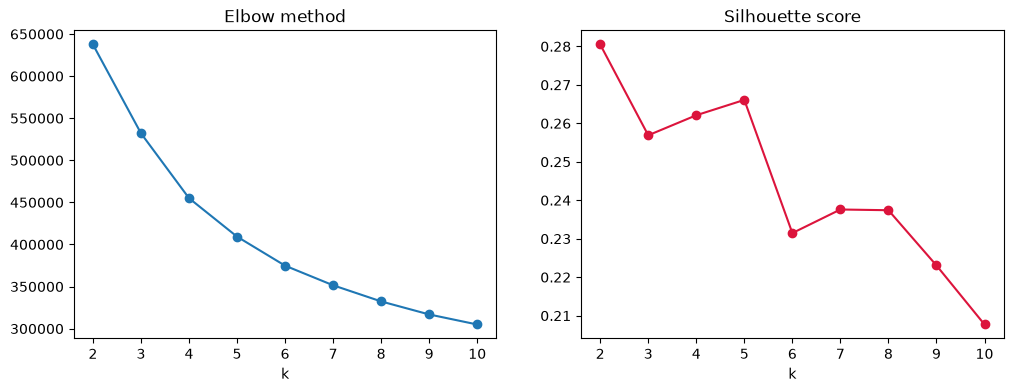

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=42))
    print(f"k={k}  silhouette={silhouette[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, marker="o"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k")
axes[1].plot(ks, silhouette, marker="o", color="crimson"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.savefig("../reports/figures/8_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
K = 4      # change this after looking at Cell 2's graphs
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = km.labels_

profile = df.groupby("cluster").agg(
    customers=("FLAG", "size"),
    theft_rate_pct=("FLAG", lambda s: round(s.mean() * 100, 1)),
    avg_usage=("mean", "median"),
    cv=("cv", "median"),
    zero_pct=("zero_pct_after_start", "median"),
    max_drop=("max_month_drop", "median"),
    summer_vs_winter=("summer_vs_winter", "median"),
    active_days=("active_days", "median"),
).round(2)
profile

,customers,theft_rate_pct,avg_usage,cv,zero_pct,max_drop,summer_vs_winter,active_days
cluster,,,,,,,,
0,7975,10.5,2.23,1.73,0.00,0.38,1.43,304.0
1,20898,9.0,7.83,0.50,0.00,0.47,1.23,1034.0
2,4534,1.9,0.00,1.00,1.00,0.00,1.00,111.0
3,8882,8.8,1.86,1.29,0.24,0.97,1.00,1031.0


Variance explained by 2 components: 0.52


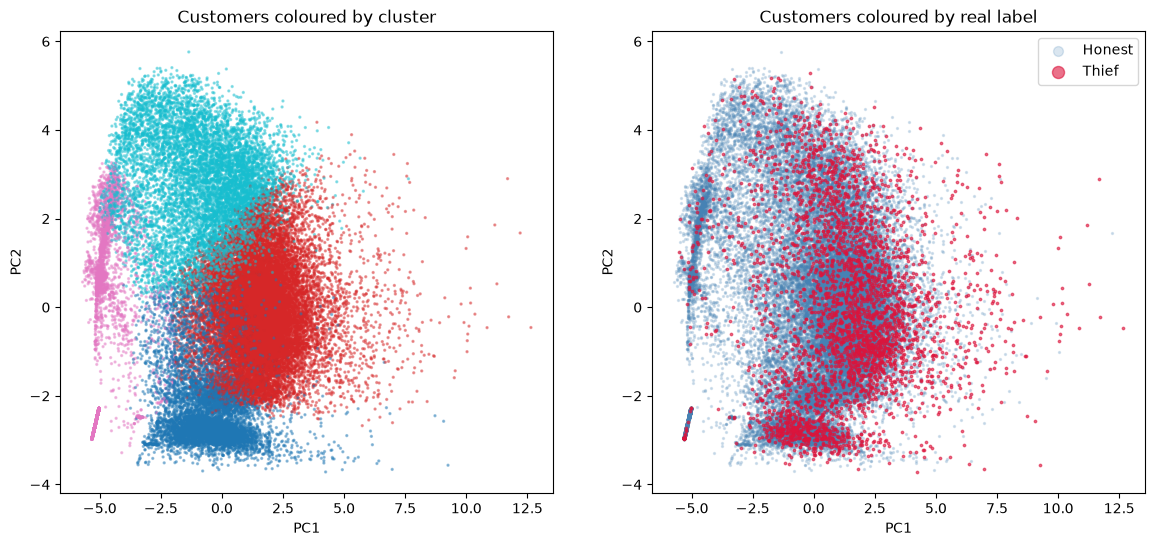

In [4]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X_scaled)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(xy[:, 0], xy[:, 1], c=df["cluster"], cmap="tab10", s=2, alpha=0.4)
axes[0].set_title("Customers coloured by cluster")

honest, thief = (y == 0).values, (y == 1).values
axes[1].scatter(xy[honest, 0], xy[honest, 1], c="steelblue", s=2, alpha=0.2, label="Honest")
axes[1].scatter(xy[thief, 0], xy[thief, 1], c="crimson", s=3, alpha=0.6, label="Thief")
axes[1].set_title("Customers coloured by real label")
axes[1].legend(markerscale=5)
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.savefig("../reports/figures/9_pca_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

iso = IsolationForest(n_estimators=300, random_state=42, n_jobs=-1).fit(X_scaled)
strangeness = -iso.decision_function(X_scaled)      # higher = more unusual

k = int(0.05 * len(y))
top = np.argsort(strangeness)[::-1][:k]

print("Isolation Forest (no labels used)")
print("  ROC-AUC:", round(roc_auc_score(y, strangeness), 3))
print("  PR-AUC :", round(average_precision_score(y, strangeness), 3))
print(f"  Top 5% most unusual: {y.iloc[top].mean()*100:.1f}% are real thieves")

Isolation Forest (no labels used)
  ROC-AUC: 0.577
  PR-AUC : 0.13
  Top 5% most unusual: 20.4% are real thieves


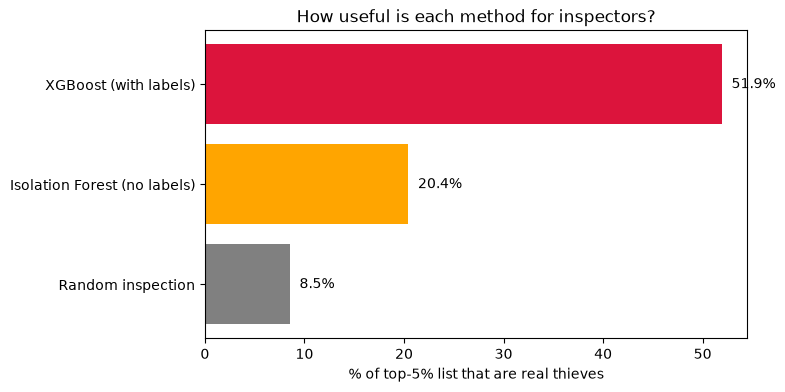

,Method,ROC-AUC,Top 5% precision (%)
0,Random inspection,0.500,8.5
1,Isolation Forest (no labels),0.577,20.4
2,XGBoost (with labels),0.803,51.9


In [6]:
comparison = pd.DataFrame({
    "Method": ["Random inspection", "Isolation Forest (no labels)", "XGBoost (with labels)"],
    "ROC-AUC": [0.50, round(roc_auc_score(y, strangeness), 3), 0.803],
    "Top 5% precision (%)": [8.5, round(y.iloc[top].mean() * 100, 1), 51.9],
})
comparison.to_csv("../reports/supervised_vs_unsupervised.csv", index=False)

plt.figure(figsize=(7, 4))
plt.barh(comparison["Method"], comparison["Top 5% precision (%)"],
         color=["gray", "orange", "crimson"])
plt.xlabel("% of top-5% list that are real thieves")
plt.title("How useful is each method for inspectors?")
for i, v in enumerate(comparison["Top 5% precision (%)"]):
    plt.text(v + 1, i, f"{v}%", va="center")
plt.savefig("../reports/figures/10_method_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
comparison

In [7]:
import joblib

scaler = StandardScaler().fit(X_log)
cluster_names = {
    0: "New / late-start meter",
    1: "Regular steady user",
    2: "Empty / inactive meter",
    3: "Erratic on/off user",
}
joblib.dump({"scaler": scaler, "kmeans": km, "names": cluster_names,
             "features": list(X.columns)},
            "../models/clusters.joblib")
print("Saved!")

Saved!
